In [277]:
import numpy as np
import FBA_ode

In [278]:
# initial conditions
x0 = np.zeros(32)  # Defining the array, x0, that will house initial concentrations
# Cytoplasm
x0[0] = 1e-9  # H2O2media 
x0[1] = 1e-9  # H2O2cytosol

x0[2] = 5e-5  # GPXr 
x0[3] = 1e-14  # GPXo 
x0[4] = 1e-14  # GPX-SG 

x0[5] = 3.68e-4  # GSH 
x0[6] = 1.78e-6  # GSSG 

x0[7] = 9e-7  # Catalase 
x0[8] = 1.0e-10  # H2O2peroxisome 

x0[9] = 1.92e-5  # Prx-SH  
x0[10] = 1e-14  # Prx-SOH 
x0[11] = 1e-14  # Prx-SOOH 
x0[12] = x0[9] * (0.5 / 100)  # Prx-SS 

x0[13] = 4.27e-7  # Trx1-SH 
x0[14] = 7.54e-8  # Trx1-SS 

x0[15] = 1.22e-4  # Pr-SH 
x0[16] = x0[15] * (0.5 / 100)  # Pr-SOH
x0[17] = x0[15] * (0.5 / 100)  # Pr-SSG 

x0[18] = 1.20e-6  # Grx-SH 
x0[19] = x0[18] * (0.5 / 100)  # Grx-SSG 

x0[20] = 1.09e-3  # Pr-(SH)2  
x0[21] = x0[20] * (0.5 / 100)  # Pr-SS

x0[22] = 3.0e-5  # NADPH 
x0[23] = 3.0e-7  # NADP+

x0[24] = 0 # superoxide media
x0[25] = 0#1e-9 # superoxide cytosol

x0[26] = 0 # superoxide dismutase reduced
x0[27] = 0 # superoxide dismutase oxidized

x0[28] = 1e-9 # steady state h2o2 intracellular

x0[29] = 1e-7 # calcium intracellular
x0[30] = 1.5e-3 # calcium extracellular
x0[31] = 1.0e-4 # calcium ER [M] ~ 0.1 mM


In [279]:
# Rxns (Cytosolic)
k = np.zeros(100)  # Defining the array, k, that will house reaction rates
# Rxns (Cytosolic)

k[0] = 2e-2  # Permeability constant (plasma membrane) (cm/s)
k[1] = 14.75e-7  # Intracellular peroxide production (M/s)
k[2] = 2.1e7  # GPx_red reacting with H2O2in (M-1*s-1)
k[3] = 4e4  # GPx_ox reacting with GSH (M-1*s-1)
k[4] = 1e7  # GPx-SSG reacting with GSH (M-1*s-1)
k[5] = 3.4e7  # Catalase reacts with H2O2 inside peroxisome (M-1*s-1)
k[6] = 5.7e-5  # Km of NADP+ (M)
k[7] = 100e-6  # Peroxiredoxin is oxidized by H2O2 (M-1*s-1)
k[8] = 0.0049e-6  # Oxidized peroxiredoxin is over-oxidized by H2O2 (M-1*s-1)
k[9] = 3e-3  # Reduction of overoxidized Prx by Srx enzyme (s-1)
k[10] = 15  # Self-catalyzed disulfide formation of Prx-SS from Prx-SOH (s-1)
k[11] = 2.1e-6 # Peroxiredoxin is reduced by Thioredoxin (M-1*s-1)
k[12] = 7.4e-05  # Auto-oxidation of GSH (s-1)
k[13] = 1e4  # Protein monothiol oxidized by H2O2 (M-1*s-1)
k[14] = 1.2e5  # Oxidized Protein monothiol glutathionylated by GSH (M-1*s-1)
k[15] = 9.1e4  # Grx-SH de-glutathionylates Protein-SSG (M-1*s-1)
k[16] = 3.7e4  # GSH de-glutathionylates Grx-SSG (M-1*s-1)
k[17] = 5e5  # Protein dithiol oxidized by H2O2 (M-1*s-1)
k[18] = 1e5  # Protein disulfide reduced by Trx (M-1*s-1)
k[19] = 3.2e6  # GSSG reduced by GR (M-1*s-1)
k[20] = 2e7  # Oxidized Thioredoxin reduced by TrxR (M-1*s-1)
k[21] = 3.75e-04  # Production of NADPH by G6P-DH (M/s)
k[22] = 3e-3  # Permeability constant (peroxisomal membrane) (cm/s)
k[23] = 4.1e-7  # GSH synthesis (M/s)
k[24] = 1.2e-8  # GSSG efflux (M/s)
k[25] = 1.2e-7  # GSH + GSSG efflux (M/s)
k[26] = 7.45e-10  # Trx_SH efflux (M/s)
k[27] = 6.97e-10  # Trx_SH synthesis (M/s)
k[28] = 0#1e-5 # nox generation of superoxide ()    #Banfi B. et al, JBC 2002
k[29] = 0#4e9 # superoxide dismutase reduction and oxidation by superoxide (M-1*s-1), from Fee J.A. & Bull C. The journal of biological chemistry 1986
k[30] = 0 # intracellular superoxide production (M/s)
k[31] = 0 # nox h2o2 production (M/s)
k[32] = 5e-7 # nox 2 (M/s?)
k[33] = 1e-7 # km nox2 (M) for activation by h2o2


# ---- new Ca2+ and NOX5 parameters (packed into k) ----
# ER Ca release via oxidized IP3R
k[34] = 1e-4    # V_rel (M/s) ER -> cyt max release
k[35] = 1e-7     # K_IP3R_H (M) H2O2 half-activation for IP3R oxidation and activation
k[36] = 4       # nH (Hill exponent H2O2→IP3R)
k[37] = 5e-7     # K_er (M) ER Ca activation for release

# SERCA uptake with H2O2 inhibition
k[38] = 1e-9    # V_SERCA (M/s)
k[39] = 1e-6     # K_ser (M) cyt Ca half-sat for SERCA uptake, # 10.1113/jphysiol.2013.269373
k[40] = 1e-5     # K_SERCA_H (M) H2O2 inhibition scale
k[41] = 2        # m_inhib (Hill for H2O2 inhibition)

# TRPM2 H2O2-gated influx
k[42] = 9e-7     # P_TRPM2 (1/s) effective permeability scale
k[43] = 5e-7     # K_TRPM2_H (M) H2O2 half-activation (~10–100 µM)
k[44] = 2.0        # p_TRPM2 (Hill exponent)

# SOCE (store-operated Ca entry) factor
k[45] = 1e-7     # P_SOCE (1/s)
k[46] = 100e-7     # K_store (M) ER Ca scale where SOCE ramps

k[47] = 2.1 # SERCA n (Hill exponent for Ca), 10.1113/jphysiol.2013.269373

# NOX5 Ca-dependent ROS production
k[48] = 5e-4    # Vmax_NOX5 (M/s)  (tune 1e-8 to 1e-7)
k[49] = 0.71e-6    # K_Ca (M) ~ 1 µM half-activation
k[50] = 4        # m_nox (Hill exponent for Ca)

k[51] = 5e-7     # K_IP3R_H_inh (M) H2O2 half-inhibition for IP3R oxidation
k[52] = 2       # mH_inh (Hill exponent H2O2 inhibition)
k[53] = 5e-6      # K_IP3R_C_inh (M) Ca half-inhibition for IP3R
k[54] = 2       # n_Ca_IP3R_act (Hill exponent Ca activation)

# ER capacity & overflow
k[55] = 1.1e-4     # C_ER_max [M]   (e.g., 0.5 mM; set well above baseline ~1e-4)
k[56] = 1e-2       # k_over  [1/s]  (how fast overflow evacuates when over cap)
k[57] = 5e-7    # K_IP3R_Ca (M) Cytosolic Ca scale for IP3R activation
# Cytosolic Ca extrusion (lumped PMCA/NCX)
k[58] = 4e-10        # 1/s  (cytosolic Ca leak rate constant), #try 6e-8 for faster degradation

# NOX5 NADPH Km (you already have Vmax & Ca gate)
k[62] = 1.4e-5                    # Km_NOX5_NADPH [M] (~14 µM)

# Duox1/2 (additional Ca-dependent ROS source)
k[63] = 0.1e-9                 # kcat_duox_low_Ca (s-1)  (tune 1e-8 to 1e-7)
k[64] = 0.87e-6                    # K_Duox_Ca (M) ~ 1 µM half-activation
k[65] = 4                           # m_duox (Hill exponent for Ca)
k[66] = 24.31e-6                    # Km_Duox_NADPH_low_Ca [M] (~14 µM)
k[67] = 11.52e-6                    # Km_Duox_NADPH_high_Ca [M] (~140 µM)

# TRPM2 Ca influx (you already have H2O2 gate) due to calcium
k[68] = 16.9e-6     # k_trpm2 ca (M) ca half-activation (~0.5 µM), doi.org/10.1073/pnas.0811725106
k[69] = 2                         # n (trpm2) ca

Initial H2O2_cytosol: 1.7161961184782212e-10 versus media 3.574696257653124e-10 for k32=1.5e-06, K_act=1e-08, permeability=0.02, scavenger=22
final calcium: 1.0985128143885475e-07 for k32=1.5e-06, K_act=1e-08, permeability=0.02, scavenger=22
Initial H2O2_cytosol: 1.7161961184782212e-10 versus media 3.574696257653124e-10 for k32=1e-07, K_act=1e-08, permeability=0.02, scavenger=22
final calcium: 1.0985128143885475e-07 for k32=1e-07, K_act=1e-08, permeability=0.02, scavenger=22
Initial H2O2_cytosol: 1.7161961184782212e-10 versus media 3.574696257653124e-10 for k32=1e-08, K_act=1e-08, permeability=0.02, scavenger=22
final calcium: 1.0985128143885475e-07 for k32=1e-08, K_act=1e-08, permeability=0.02, scavenger=22


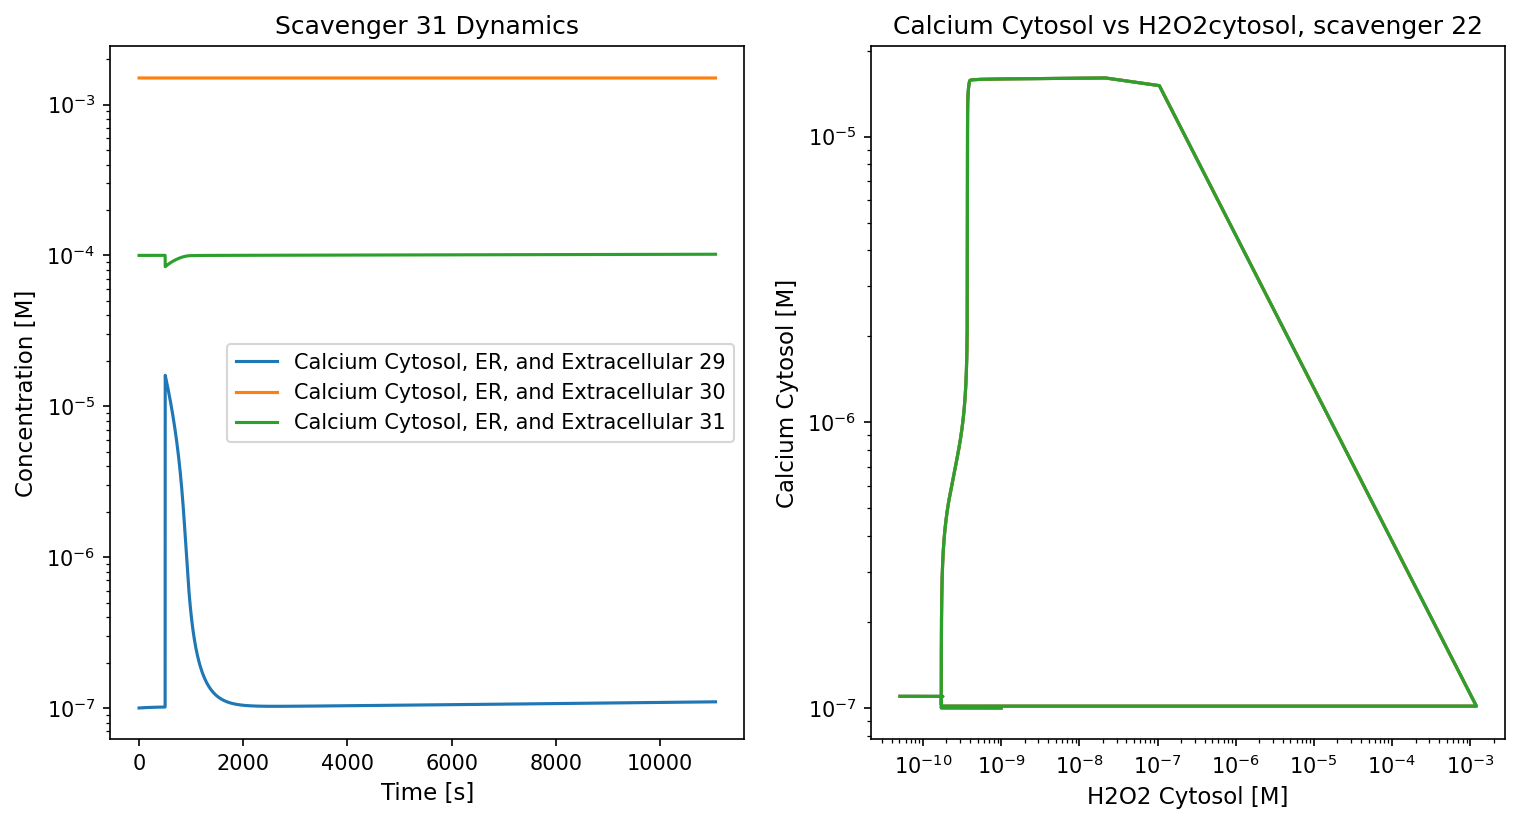

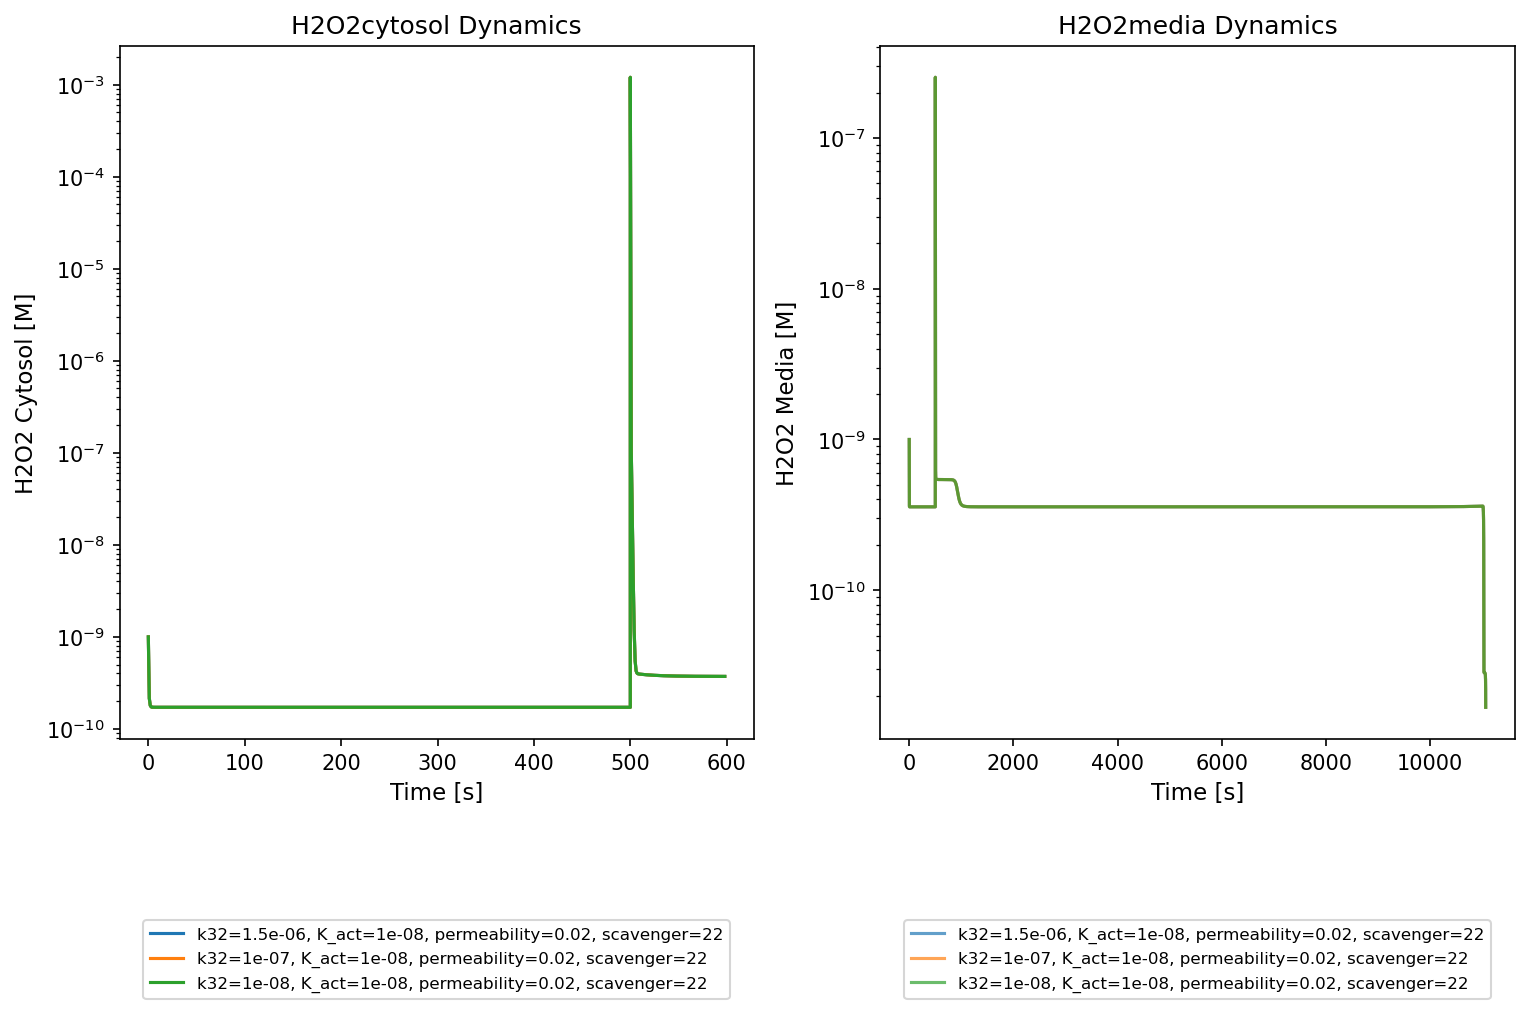

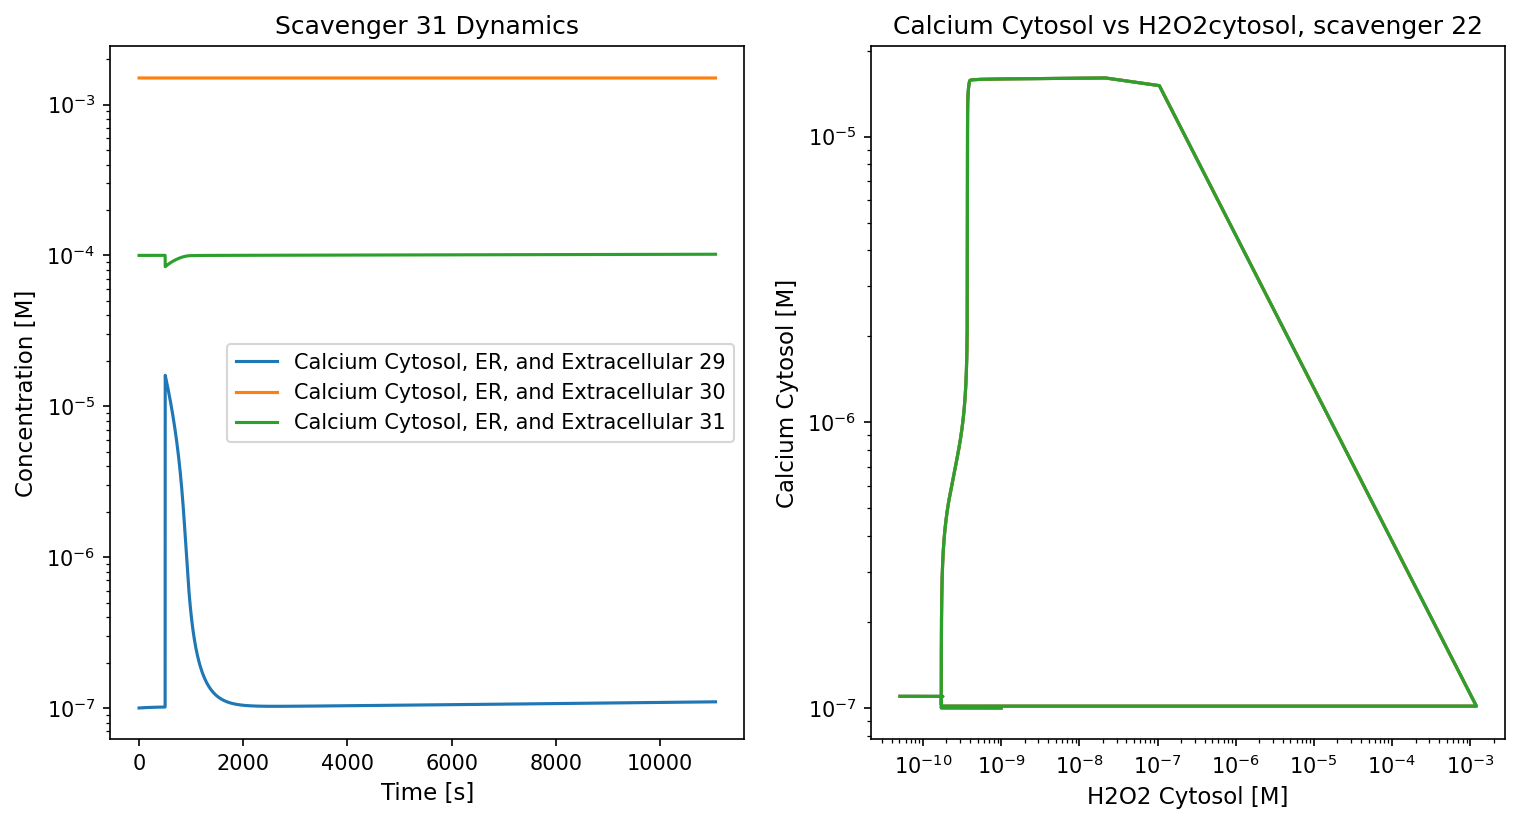

In [ ]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve

import matplotlib as mpl
import matplotlib.pyplot as plt

# Reset any styles/fonts changed earlier
plt.style.use('default')
mpl.rcParams.update(mpl.rcParamsDefault)

# Set sane, consistent sizes
mpl.rcParams.update({
    'font.family': 'DejaVu Sans',   # or 'Arial' if installed
    'font.weight': 'normal',
    'figure.dpi': 150,
    'savefig.dpi': 150,
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 12,
})
# Define the parameterized model (copy your full ODEs here)
def model_noref_param(x, t, k, x_base):
    dxdt = np.zeros_like(x)

    # ===== Calcium–ROS crosstalk using k[...] and x[...] only =====
    H   = x[1]     # H2O2 cytosol
    C   = x[29]    # Ca cytosol
    Cext= x[30]    # Ca extracellular (constant ~1-2 mM)
    Cer = x[31]    # Ca ER pool

    # --- Unpack from k ---
    V_IP3R     = k[34]; K_IP3R_H = k[35]; nH = k[36]; K_er = k[37]
    V_SERCA   = k[38]; K_ser    = k[39]; K_SERCA_H = k[40]; m_inhib = k[41]
    P_TRPM2   = k[42]; K_TRPM2_H= k[43]; p_TRPM2 = k[44]
    P_SOCE    = k[45]; K_store  = k[46]
    k_out     = k[47]
    Vmax_NOX5 = k[48]; K_Ca     = k[49]; m_nox = k[50]

    # --- Helper gates (pure functions of species & k) ---
    Ca_gate_IP3R = (x[29])**k[54] / (k[57]**k[54] + (x[29])**k[54]) if x[29] > 0 else 0.0 # Activated by cyt Ca
    Ca_IP3R_inhib = 1.0/(1.0 + (x[29]/k[53])**2) if x[29] > 0 else 0.0 # Inhibited by high Ca
    h2o2_gate_IP3R = (H**nH)/(K_IP3R_H**nH + H**nH) if H > 0 else 0.0 # activation by H2o2
    H2O2_inhibit_IP3R = (k[51]**k[52]) / (k[51]**k[52] + H**k[52]) if H > 0 else 0.0 # inhibition by very high H2O2
    SERCA_inhb = 1.0/(1.0 + (H/K_SERCA_H)**m_inhib) if H > 0 else 1.0
    H2O2_gate_TRPM2 = (H**p_TRPM2)/(K_TRPM2_H**p_TRPM2 + H**p_TRPM2) if H > 0 else 0.0
    Ca_gate_TRPM2 = (x[29]**k[69])/((k[68]**k[69]) + (x[29]**k[69])) if x[29] > 0 else 0.0
    SOCE_drive = K_store/(K_store + Cer)       # ramps as ER depletes

    # --- Fluxes (units consistent with your H2O2 model scaling) ---
    J_IP3R     = V_IP3R   * h2o2_gate_IP3R * Ca_gate_IP3R \
        * Ca_IP3R_inhib * H2O2_inhibit_IP3R * (Cer - C) / (K_er + Cer) if (Cer - C) > 0 else 0.0 # ER -> cyt release via IP3R
    #print(Ca_gate_IP3R,h2o2_gate_IP3R,Ca_IP3R_inhib,H2O2_inhibit_IP3R,J_IP3R)
    J_SERCA   = V_SERCA * (C**k[47]/(k[39]**k[47] + C**k[47])) * SERCA_inhb if C > 0 else 0.0 # cyt -> ER uptake by SERCA
    J_in_TRPM2= P_TRPM2 * H2O2_gate_TRPM2 * Ca_gate_TRPM2 * (x[30] - x[29]) if (x[30] - x[29]) > 0 else 0.0 # PM influx via TRPM2
    J_in_SOCE = P_SOCE  * SOCE_drive * (x[30] - x[29]) if (x[30] - x[29]) > 0 else 0.0 # PM influx via SOCE to restore ER

    # --- ER capacity gating for SERCA (prevents overfilling) ---
    cap = 1.0 - (x[31] / k[55])         # linear headroom fraction
    cap = 0.0 if cap < 0.0 else cap   # clamp to [0, 1]
    J_SERCA *= cap                    # SERCA stops as ER approaches capacity

    # --- Overflow if ER exceeds the cap (hard push back to cytosol) ---
    J_over = k[56] * cap * x[31] if cap < 0.0 else 0.0
    J_out = k[58] * (x[29])/ (5e-6 + (x[29]))  if x[29] > 0 else 0.0 # cytosolic Ca extrusion (PMCA/NCX lumped)
    # --- NOX5 Ca-dependent ROS production ---
    nox2 = k[32] * (x[1]**6)/(k[33]**6 + x[1]**6) if x[1] > 0 else 0.0 #nox2
    # NOX5 with NADPH limitation
    nox5 = k[48] * (x[29]**k[50])/(k[49]**k[50] + x[29]**k[50]) \
                * (x[22]/(k[62] + x[22])) if x[29] > 0 or x[22] > 0 else 0.0

    km_duox = k[66] - (k[66] - k[67]) * (x[29]**k[65])/(k[64]**k[65] + x[29]**k[65]) if x[29] > 0 else k[67]
    duox = k[63] * x[22]/(km_duox + x[22])

    #print("nox2, nox5, duox:", nox2, nox5, duox)
    k_diff = 1
    dxdt[0] = (k[0]*(x[1] - x[0]) * 10e-3 * 5.3e-6 * (1e9)) + nox2 + duox #- k_diff * x[0] + k[31] # extracellular peroxide

    dxdt[1] = (((k[0] * x[0] * 10e-3 * 5.3e-6) / (1.15e-12))
               - ((k[0] * x[1] * 10e-3 * 5.3e-6) / (1.15e-12))
               - 2 * (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14)              # peroxisomal H2O2     
               - k[2] * x[2] * x[1]                             # GPx reduction of H2O2
               - k[5] * x[7] * x[1]                                   # catalase reaction
               - k[7] * x[9] * x[1]                                   # peroxiredoxin oxidation
               - k[8] * x[10] * x[1]                                  # overoxidized peroxiredoxin
               - k[13] * x[15] * x[1]                                 # Protein monothiol oxidation
               - k[17] * x[20] * x[1]                                 # Protein dithiol oxidation
               + k[1]                                                          # peroxide production due to ETC leak
               + nox5)                                                        # nox5 h2o2 production
    
    #GPXr
    dxdt[2] = (- k[2] * x[2] * x[1]
               + k[4] * x[4] * x[5])
    #GPXo
    dxdt[3] = k[2] * x[2] * x[1] - k[3] * x[3] * x[5] 
    #GPX-SG
    dxdt[4] = k[3] * x[3] * x[5] - k[4] * x[4] * x[5]
    #GSH
    dxdt[5] = (- k[3] * x[3] * x[5]
               - k[4] * x[4] * x[5]
               - 2 * k[12] * x[5]
               - k[14] * x[16] * x[5]
               - k[16] * x[16] * x[5]
               + 2 * k[19] * x[6] * x[22]
               + k[23] 
               - k[25])
    #GSSG
    dxdt[6] = (k[4] * x[4]* x[5] 
               + k[12] * x[5] 
               + k[16] * x[19] * x[5] 
               - k[19] * x[6] * x[22] if x[6] > 0 and x[22] > 0 else 0.0
               - k[24] * x[6] / x_base[6] if x_base[6] > 0 else 0.0
               - k[25] * x[6] / x_base[6] if x_base[6] > 0 else 0.0)

    dxdt[7] = 0
    dxdt[8] = ((k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14)            # peroxisomal H2O2
               - k[5] * x[7] * x[8])
    
    #Prx-SH
    dxdt[9] = (- k[7] * x[9] * x[1]                                 # peroxiredoxin oxidation by H2O2, rates = 4e7 M-1s-1
               + k[11] * x[12] * x[13])                             # reduction of peroxiredoxin by thioredoxin
    #Prx-SOH
    dxdt[10] = (k[7] * x[9] * x[1] 
                - k[8] * x[10] * x[1]                           # overoxidized peroxiredoxin by H2O2    
                + k[9] * x[11]                                      # reduction of overoxidized peroxiredoxin by sulfiredoxin
                - k[10] * x[10])                                # self-catalyzed disulfide formation of Prx-SS from Prx-SOH
    #Prx-SOOH
    dxdt[11] = (k[8] * x[10] * x[1]                                 # reduction of peroxiredoxin by thioredoxin
                - k[9] * x[11])                                    # reduction of overoxidized peroxiredoxin by sulfiredoxin
    #Prx-SS
    dxdt[12] = (k[10] * x[10]                                   # self-catalyzed disulfide formation of Prx-SS from Prx-SOH
                - k[11] * x[12] * x[13])
    #Trx1-SH
    dxdt[13] = (- k[11] * x[12] * x[13] 
                - k[18] * x[21] * x[13] 
                + k[20] * x[14] * x[22] 
                - k[26] 
                + k[27])
    #Trx1-SS
    dxdt[14] = (k[11] * x[12] * x[13] 
                + k[18] * x[21] * x[13] 
                - k[20] * x[14] * x[22])

    dxdt[15] = (- k[13] * x[15] * (x[1])
                + k[15] * x[18] * (x[17]))

    dxdt[16] = k[13] * x[15] * x[1] - k[14] * x[16] * x[5]
    dxdt[17] = k[14] * x[16] * x[5] - k[15] * x[18] * x[17]
    dxdt[18] = k[16] * x[19] * x[5] - k[15] * x[18] * x[17]
    
    dxdt[19] = (k[15] * x[18] * x[17] 
                - k[16] * x[19] * x[5])
    
    #Pr-(SH)2
    dxdt[20] = - k[17] * x[20] * x[1] + k[18] * x[21] * x[13]
    dxdt[21] = k[17] * x[20] * x[1] - k[18] * x[21] * x[13]

    #NADPH
    dxdt[22] = (- k[19] * x[6] * x[22] 
                - k[20] * x[14] * x[22] 
                #- k[28] * x[22]                                         # nox generation of superoxide
                - (2 * nox2 if x[22] > 0 else 0.0)
                - (2 * nox5 if x[22] > 0 else 0.0)
                + (k[21] * x[23] / (k[6] + x[23]) if x[23] > 0 or x[22] > 0 else 0.0))
    #NADP+
    dxdt[23] = (k[19] * x[6] * x[22] 
                + k[20] * x[14] * x[22] 
                #+ k[28] * x[22]                                         # nox generation of superoxide and nadp+
                + 2 * nox2
                + 2 * nox5
                - (k[21] * x[23] / (k[6] + x[23]) if x[23] > 0 else 0.0))
    #superoxide media
    dxdt[24] = 0
    #superoxide cytosol
    dxdt[25] = 0
    #SOD reduced
    dxdt[26] = 0
    #SOD oxidized
    dxdt[27] = 0

    # --- Calcium balances --
    dxdt[29] = J_IP3R + J_in_TRPM2 + J_in_SOCE + J_over - J_SERCA - J_out            # d[Ca_cyt]/dt
    dxdt[30] = 0                                                     # d[Ca_ext]/dt
    dxdt[31] = J_SERCA - J_IP3R - J_over                           # d[Ca_ER]/dt
    #print(dxdt[29],dxdt[31])

    return dxdt

# Parameter lists
k_list = [1.5e-6]
K_act_list = [1e-8]
permeability_coefficient_list = [2e-2]#24e-2, 2e-2, 1e-3,1e-4,1e-5]

# Store results for plotting
results = []
# Initial conditions

xnew = x0.copy()
# Scaling factor for consumption rates
consumption_scale = 1 # Adjust this value to tune steady state

# Scale the major consumption reactions
k[2] *= consumption_scale   # GPx
k[5] *= consumption_scale   # Catalase  
k[7] *= consumption_scale   # Prx
k[13] *= consumption_scale  # Protein monothiol
k[17] *= consumption_scale  # Protein dithiol

# k[1] = 6e-7 #ss at 23.75e-7
# k[48] = 3.02e-6
# k[32] = 8.87e-8
# k[49] = 1e-8
# k[22] = 0
# k_new[2] = 0
scavengers = [22]#22, 2, 5, 7, 8, 13, 17]  # Try more than one scavenger
k_list = [1.5e-6, 1e-7, 1e-8]       
xnew[0] = 1e-9
xnew[1] = 1e-9

# Alternative time setup
t = np.linspace(0, 36000, 36001)
t1 = np.linspace(0, 500, 501)  # Times from 0 to 500
t2 = np.linspace(500, 36000, 35500)  # Times from 500 to 3600

# Iterate and solve
for scavenger in scavengers:
    for permeability_coefficient in permeability_coefficient_list:
        for k32 in k_list:
            for K_act in K_act_list:
                k_new = k.copy()
                k_new[0] = permeability_coefficient
                #k_new[scavenger] = k[scavenger] * 0.1  # Reduce scavenger concentration by 90%
                #k_new[48] = k32
                #k_new[scavenger] = 0  # Reduce scavenger concentration by 90%
                # --- Change only the times and keep the same structure ---
                ode_func = lambda t, y: model_noref_param(y, t1, k_new, xnew)
                sol1 = solve_ivp(ode_func, (0, t1[-1]), xnew, t_eval=t1, method='Radau', atol=1e-10, rtol=1e-8)       
                #print(sol1.shape)  # shape should be (32, 501)
                xnew1 = sol1.y[:, -1].copy()  # Get the last state as 1D array
                xnew1[1] = xnew1[1] + 0.0012  # Add perturbation to H2O2_cytosol (index 1, not 0)

                ode_func2 = lambda t, y: model_noref_param(y, t2, k_new, xnew)
                sol2 = solve_ivp(ode_func2, (t2[0], t2[-1]), xnew1, t_eval=t2, method='Radau', atol=1e-10, rtol=1e-8)
                # Reshape xnew1 to be a column vector (2D array with 1 column)
                #print(sol2.y.shape)  # shape should be (32, 3600)

                t = np.concatenate((sol1.t, sol2.t))  # now length = 101 + 3600 = 3701
                solution = np.concatenate((sol1.y, sol2.y), axis=1)
                #print(solution.shape)  # shape should be (32, 3701)
                results.append({
                    'x': solution,
                    'Nox2 Production Rate [M/s]': k32,
                    'K_act [M]': K_act,
                    'H2O2_cytosol': solution[1],
                    'H2O2_media': solution[0],
                    't': t,
                    'permeability_coefficient': permeability_coefficient,
                    'scavenger_reduced': scavenger
                })

plt.figure(figsize=(12, 6))

# Subplot 1: H2O2 Cytosol
plt.subplot(1, 2, 1)
for res in results:
    label = f"k32={res['Nox2 Production Rate [M/s]']}, K_act={res['K_act [M]']}, permeability={res['permeability_coefficient']}, scavenger={res['scavenger_reduced']}"
    plt.plot(res['t'][0:600], res['H2O2_cytosol'][0:600], label=label)
    #print(f"Initial H2O2_cytosol: {res['H2O2_cytosol'][50]} versus media {res['H2O2_media'][50]} for {label}")
plt.xlabel('Time [s]')
plt.ylabel('H2O2 Cytosol [M]')
plt.title('H2O2cytosol Dynamics')
plt.yscale('log')
plt.legend(bbox_to_anchor=(0.5, -0.25), loc='upper center', fontsize=8, ncol=1)

# Subplot 2: H2O2 Media
plt.subplot(1, 2, 2)
for res in results:
    label = f"k32={res['Nox2 Production Rate [M/s]']}, K_act={res['K_act [M]']}, permeability={res['permeability_coefficient']}, scavenger={res['scavenger_reduced']}"
    plt.plot(res['t'][0::], res['H2O2_media'][0::], label=label, alpha=0.7)
    print(f"Initial H2O2_cytosol: {res['H2O2_cytosol'][50]} versus media {res['H2O2_media'][50]} for {label}")
    print(f"final calcium: {res['x'][29,-1]} for {label}")
plt.xlabel('Time [s]')
plt.ylabel('H2O2 Media [M]')
plt.title('H2O2media Dynamics')
plt.yscale('log')
plt.legend(bbox_to_anchor=(0.5, -0.25), loc='upper center', fontsize=8, ncol=1)

plt.figure(figsize=(12, 6))
plt.subplot(1,2,1)
for scavenger in [29,30,31]:
    plt.plot(res['t'][0::], res['x'][scavenger, 0::], label=f'Calcium Cytosol, ER, and Extracellular {scavenger}')
    if any(res['x'][scavenger, 0:30] <= 0):
        print(f"Warning: Scavenger {scavenger} has non-positive values")
        print(res['x'][scavenger, -1])
plt.xlabel('Time [s]')
plt.ylabel('Concentration [M]')
plt.title(f'Scavenger {scavenger} Dynamics')
plt.yscale('log') 
plt.legend()

plt.subplot(1,2,2)
for res in results:
    plt.plot(res['H2O2_cytosol'], res['x'][29, :], label=f'Calcium Cytosol vs H2O2cytosol, scavenger {res["scavenger_reduced"]}')
    if any(res['x'][29, 0:30] <= 0):
        print(f"Warning: Scavenger {res['scavenger_reduced']} has non-positive values")
        print(res['x'][29, -1])
plt.xlabel('H2O2 Cytosol [M]')
plt.ylabel('Calcium Cytosol [M]')
plt.title(f'Calcium Cytosol vs H2O2cytosol, scavenger {res["scavenger_reduced"]}')
plt.xscale('log')
plt.yscale('log')
plt.show()

12 12


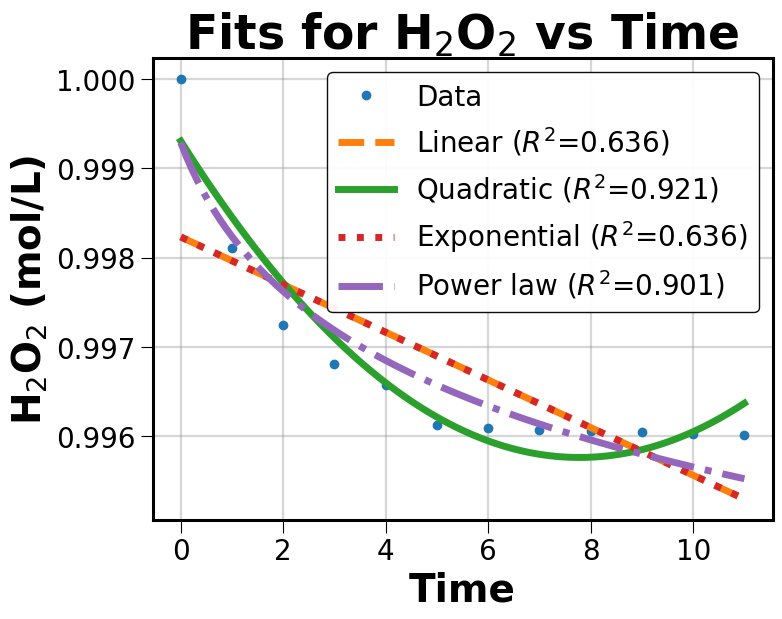

Linear fit:    y = -0.0003 * t + 0.9982      (R² = 0.636)
Quadratic fit: y = 0.0001 * t^2 + -0.0009 * t + 0.9993   (R² = 0.921)
Exponential fit: y = 0.9982 * exp(-0.0003 * t)   (R² = 0.636)
Power law fit:   y = 0.9993 * (t + 1)^-0.0015   (R² = 0.901)


In [281]:
data1 = np.array([
    1.00605e-09,
    1.00415e-09,
    1.00328e-09,
    1.00284e-09,
    1.00260e-09,
    1.00215e-09,
    1.00212e-09,
    1.00210e-09,
    1.00208e-09,
    1.00207e-09,
    1.00205e-09,
    1.00204e-09,
], dtype=float)

t = np.linspace(0, len(data1) - 1, len(data1))
max_data = np.max(data1)
data = data1 / max_data

print(len(t), len(data))


import matplotlib.pyplot as plt
import numpy as np

def r2(y, y_pred):
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return 1 - ss_res / ss_tot

# Linear fit
coeffs_lin = np.polyfit(t, data, 1)
data_lin = np.polyval(coeffs_lin, t)
r2_lin = r2(data, data_lin)

# Quadratic fit
coeffs_quad = np.polyfit(t, data, 2)
data_quad = np.polyval(coeffs_quad, t)
r2_quad = r2(data, data_quad)

# Exponential fit: y = a * exp(bx)
b_exp, loga_exp = np.polyfit(t, np.log(data), 1)
a_exp = np.exp(loga_exp)
data_exp = a_exp * np.exp(b_exp * t)
r2_exp = r2(data, data_exp)

# Power law fit: y = a * x^b (not meaningful if t=0, so skip or offset t if needed)
# If you want to fit a power law, use t+1 to avoid log(0)
logt = np.log(t + 1)
logd = np.log(data)
b_pow, loga_pow = np.polyfit(logt, logd, 1)
a_pow = np.exp(loga_pow)
data_pow = a_pow * (t + 1) ** b_pow
r2_pow = r2(data, data_pow)

# Plot all fits
t_fit = np.linspace(min(t), max(t), 100)
plt.figure(figsize=(8,6))
plt.plot(t, data, 'o', label='Data')
plt.plot(t_fit, np.polyval(coeffs_lin, t_fit), '--', label=f'Linear ($R^2$={r2_lin:.3f})')
plt.plot(t_fit, np.polyval(coeffs_quad, t_fit), '-', label=f'Quadratic ($R^2$={r2_quad:.3f})')
plt.plot(t_fit, a_exp * np.exp(b_exp * t_fit), ':', label=f'Exponential ($R^2$={r2_exp:.3f})')
plt.plot(t_fit, a_pow * (t_fit + 1) ** b_pow, '-.', label=f'Power law ($R^2$={r2_pow:.3f})')
plt.xlabel('Time')
plt.ylabel('H$_2$O$_2$ (mol/L)')
plt.title('Fits for H$_2$O$_2$ vs Time')
plt.legend()
# plt.yscale('log')
plt.grid(True)
plt.show()

# Linear fit coefficients
m = coeffs_lin[0]
b_lin = coeffs_lin[1]

# Quadratic fit coefficients
a = coeffs_quad[0]
b_quad = coeffs_quad[1]
c = coeffs_quad[2]

# Linear fit: y = m * t + b
y_lin = f"{m:.4f} * t + {b_lin:.4f}     # R² = {r2_lin:.3f}"

# Quadratic fit: y = a * t^2 + b * t + c
y_quad = f"{a:.4f} * t^2 + {b_quad:.4f} * t + {c:.4f}   # R² = {r2_quad:.3f}"

# Exponential fit: y = a * exp(b * t)
y_exp = f"{a_exp:.4f} * exp({b_exp:.4f} * t)       # R² = {r2_exp:.3f}"

# Power law fit: y = a * (t + 1)^b
y_pow = f"{a_pow:.4f} * (t + 1)^{b_pow:.4f}        # R² = {r2_pow:.3f}"

print("Linear fit:    y = {:.4f} * t + {:.4f}      (R² = {:.3f})".format(m, b_lin, r2_lin))
print("Quadratic fit: y = {:.4f} * t^2 + {:.4f} * t + {:.4f}   (R² = {:.3f})".format(a, b_quad, c, r2_quad))
print("Exponential fit: y = {:.4f} * exp({:.4f} * t)   (R² = {:.3f})".format(a_exp, b_exp, r2_exp))
print("Power law fit:   y = {:.4f} * (t + 1)^{:.4f}   (R² = {:.3f})".format(a_pow, b_pow, r2_pow))

toggle nox2 production rate for biphasic effect

In [282]:
k = np.zeros(100)  # Defining the array, k, that will house reaction rates
        # Rxns (Cytosolic)

k[0] = 2e-2  # Permeability constant (plasma membrane) (cm/s)
k[1] = 1.1e-7  # Intracellular peroxide production (M/s)
k[2] = 2.1e7  # GPx_red reacting with H2O2in (M-1*s-1)
k[3] = 4e4  # GPx_ox reacting with GSH (M-1*s-1)
k[4] = 1e7  # GPx-SSG reacting with GSH (M-1*s-1)
k[5] = 3.4e7  # Catalase reacts with H2O2 inside peroxisome (M-1*s-1)
k[6] = 5.7e-5  # Km of NADP+ (M)
k[7] = 100e-6  # Peroxiredoxin is oxidized by H2O2 (M-1*s-1)
k[8] = 0.0049e-6  # Oxidized peroxiredoxin is over-oxidized by H2O2 (M-1*s-1)
k[9] = 3e-3  # Reduction of overoxidized Prx by Srx enzyme (s-1)
k[10] = 15  # Self-catalyzed disulfide formation of Prx-SS from Prx-SOH (s-1)
k[11] = 2.1e-6 # Peroxiredoxin is reduced by Thioredoxin (M-1*s-1)
k[12] = 7.4e-05  # Auto-oxidation of GSH (s-1)
k[13] = 1e4  # Protein monothiol oxidized by H2O2 (M-1*s-1)
k[14] = 1.2e5  # Oxidized Protein monothiol glutathionylated by GSH (M-1*s-1)
k[15] = 9.1e4  # Grx-SH de-glutathionylates Protein-SSG (M-1*s-1)
k[16] = 3.7e4  # GSH de-glutathionylates Grx-SSG (M-1*s-1)
k[17] = 5e5  # Protein dithiol oxidized by H2O2 (M-1*s-1)
k[18] = 1e5  # Protein disulfide reduced by Trx (M-1*s-1)
k[19] = 3.2e6  # GSSG reduced by GR (M-1*s-1)
k[20] = 2e7  # Oxidized Thioredoxin reduced by TrxR (M-1*s-1)
k[21] = 3.75e-04  # Production of NADPH by G6P-DH (M/s)
k[22] = 3e-3  # Permeability constant (peroxisomal membrane) (cm/s)
k[23] = 4.1e-7  # GSH synthesis (M/s)
k[24] = 1.2e-8  # GSSG efflux (M/s)
k[25] = 1.2e-7  # GSH + GSSG efflux (M/s)
k[26] = 7.45e-10  # Trx_SH efflux (M/s)
k[27] = 6.97e-10  # Trx_SH synthesis (M/s)
k[28] = 0#1e-5 # nox generation of superoxide ()    #Banfi B. et al, JBC 2002
k[29] = 0#4e9 # superoxide dismutase reduction and oxidation by superoxide (M-1*s-1), from Fee J.A. & Bull C. The journal of biological chemistry 1986
k[30] = 0 # intracellular superoxide production (M/s)
k[31] = 0 # nox h2o2 production (M/s)
k[32] = 1.765e-7 # nox 2 (M/s?)   # activates runaway at 1.8e-7
k[33] = 1e-7 # km nox2 (M) for activation by h2o2


# ---- new Ca2+ and NOX5 parameters (packed into k) ----
# ER Ca release via oxidized IP3R
k[34] = 1e-4    # V_rel (M/s) ER -> cyt max release
k[35] = 1e-7     # K_IP3R_H (M) H2O2 half-activation for IP3R oxidation and activation
k[36] = 4       # nH (Hill exponent H2O2→IP3R)
k[37] = 5e-7     # K_er (M) ER Ca activation for release

# SERCA uptake with H2O2 inhibition
k[38] = 2.5e-7     # V_SERCA (M/s)
k[39] = 1e-6     # K_ser (M) cyt Ca half-sat for SERCA uptake, # 10.1113/jphysiol.2013.269373
k[40] = 1e-6     # K_SERCA_H (M) H2O2 inhibition scale
k[41] = 2        # m_inhib (Hill for H2O2 inhibition)

# TRPM2 H2O2-gated influx
k[42] = 5e-5     # P_TRPM2 (1/s) effective permeability scale
k[43] = 5e-7     # K_TRPM2_H (M) H2O2 half-activation (~10–100 µM)
k[44] = 2.0        # p_TRPM2 (Hill exponent)

# SOCE (store-operated Ca entry) factor
k[45] = 1.5e-6     # P_SOCE (1/s)
k[46] = 100e-7     # K_store (M) ER Ca scale where SOCE ramps

k[47] = 2.1 # SERCA n (Hill exponent for Ca), 10.1113/jphysiol.2013.269373

# NOX5 Ca-dependent ROS production
k[48] = 5e-7    # Vmax_NOX5 (M/s)  (tune 1e-8 to 1e-7)
k[49] = 0.71e-6    # K_Ca (M) ~ 1 µM half-activation
k[50] = 4        # m_nox (Hill exponent for Ca)

k[51] = 5e-7     # K_IP3R_H_inh (M) H2O2 half-inhibition for IP3R oxidation
k[52] = 2       # mH_inh (Hill exponent H2O2 inhibition)
k[53] = 5e-6      # K_IP3R_C_inh (M) Ca half-inhibition for IP3R
k[54] = 2       # n_Ca_IP3R_act (Hill exponent Ca activation)

# ER capacity & overflow
k[55] = 1.1e-4     # C_ER_max [M]   (e.g., 0.5 mM; set well above baseline ~1e-4)
k[56] = 1e-1       # k_over  [1/s]  (how fast overflow evacuates when over cap)
k[57] = 5e-7    # K_IP3R_Ca (M) Cytosolic Ca scale for IP3R activation
# Cytosolic Ca extrusion (lumped PMCA/NCX)
k[58] = 1e-9        # 1/s  (cytosolic Ca leak rate constant)

# NOX5 NADPH Km (you already have Vmax & Ca gate)
k[62] = 1.4e-5                    # Km_NOX5_NADPH [M] (~14 µM)

# Duox1/2 (additional Ca-dependent ROS source)
k[63] = 1e-9                 # kcat_duox_low_Ca (s-1)  (tune 1e-8 to 1e-7)
k[64] = 0.87e-6                    # K_Duox_Ca (M) ~ 1 µM half-activation
k[65] = 4                           # m_duox (Hill exponent for Ca)
k[66] = 24.31e-6                    # Km_Duox_NADPH_low_Ca [M] (~14 µM)
k[67] = 11.52e-6                    # Km_Duox_NADPH_high_Ca [M] (~140 µM)

# TRPM2 Ca influx (you already have H2O2 gate) due to calcium
k[68] = 16.9e-6     # k_trpm2 ca (M) ca half-activation (~0.5 µM), doi.org/10.1073/pnas.0811725106
k[69] = 2                         # n (trpm2) ca

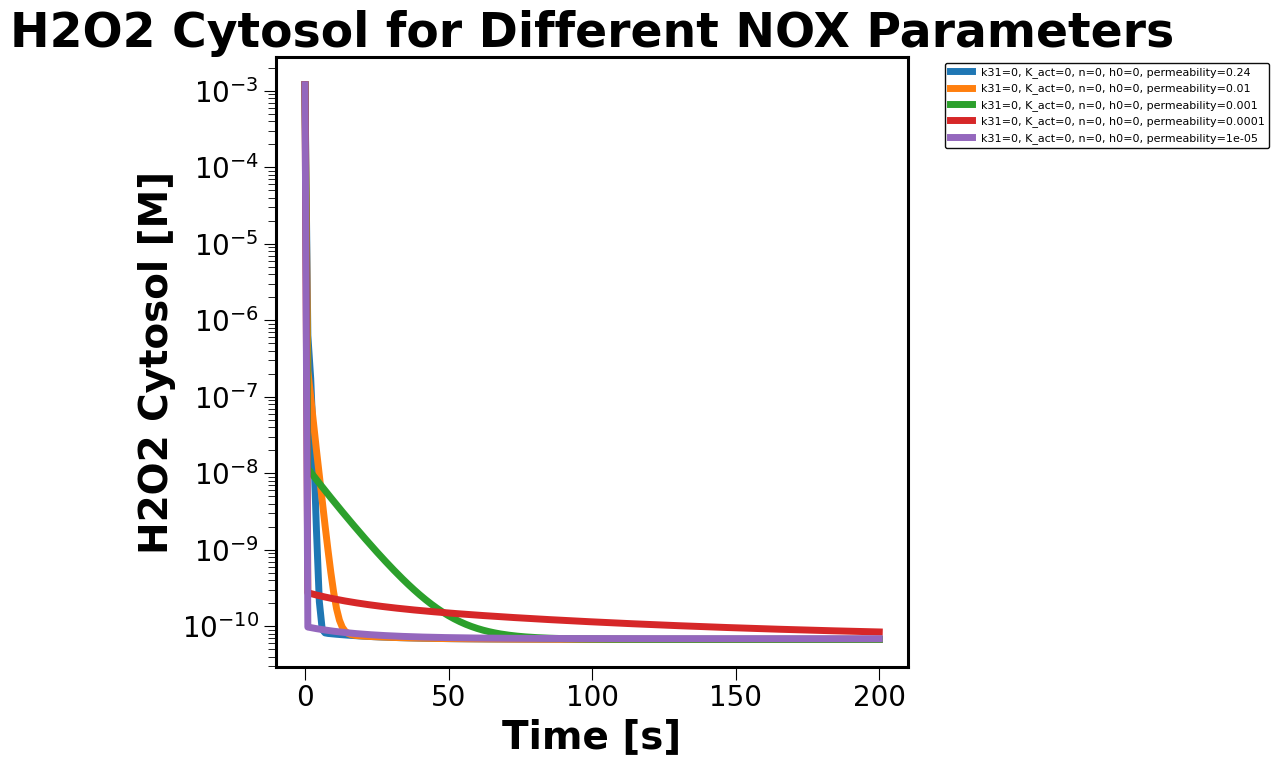

In [283]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parameter lists
k31_list = [0]#[8.87e-8]
K_act_list = [0]#[1e-9, 1e-8]
n_list = [0]#[1,3]
h_baseline_list = [0]#[4.5e-11, 1e-9]
permeability_coefficient_list = [24e-2, 1e-2, 1e-3, 1e-4, 1e-5]

# Store results for plotting
results = []
# Initial conditions

xnew = x0.copy()

xnew[1] = 0.0012  # Set initial H2O2cytosol concentration

# Define the parameterized model (copy your full ODEs here)
def model_noref_param(x, t, k, xnew, k31, K_act, n, h_baseline, permeability_coefficient_list):
    k = k.copy()
    k[31] = k31
    def nox_h2o2_rate(x, Vmax, K_act, n, h_baseline):
        h = max(x[1] - h_baseline, 0.0)
        f = (h**n) / (K_act**n + h**n) if h > 0 else 0.0
        return Vmax * f
    dxdt = np.zeros_like(x)
    k31_hill = nox_h2o2_rate(x, Vmax=k[31], K_act=K_act, n=n, h_baseline=h_baseline)
    k[0] = permeability_coefficient_list

    dxdt[0] = (k[0] * (x[1] - x[0]) * 10e-3 * 1.02e-5 * (1e9)) + k31_hill
    # --- Copy the rest of your ODEs from model_noref here ---

    dxdt[1] = (((k[0] * x[0] * 10e-3 * 5.3e-6) / (1.15e-12))
               - ((k[0] * x[1] * 10e-3 * 5.3e-6) / (1.15e-12))
               #- 2 * (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14)              # peroxisomal H2O2     
               - k[2] * x[2] * x[1]                             # GPx reduction of H2O2
               - k[5] * x[7] * x[1]                                   # catalase reaction
               - k[7] * x[9] * x[1]                                   # peroxiredoxin oxidation
               - k[8] * x[10] * x[1]                                  # overoxidized peroxiredoxin
               - k[13] * x[15] * x[1]                                 # Protein monothiol oxidation
               - k[17] * x[20] * x[1]                                 # Protein dithiol oxidation
               + k[1]                                                          # intracellular peroxide production
               + k[29] * x[25] * x[27])                                      # superoxide dismutase reduction and oxidation by superoxide

    dxdt[2] = (- k[2] * x[2] * x[1]
               + k[4] * x[4] * x[5])
    
    dxdt[3] = k[2] * x[2] * x[1] - k[3] * x[3] * x[5]
    dxdt[4] = k[3] * x[3] * x[5] - k[4] * x[4] * x[5]
    dxdt[5] = (- k[3] * x[3] * x[5]
               - k[4] * x[4] * x[5]
               - 2 * k[12] * x[5]
               - k[14] * x[16] * x[5]
               - k[16] * x[16] * x[5]
               + 2 * k[19] * x[6] * x[22]
               + k[23] 
               - k[25])
    dxdt[6] = (k[4] * x[4] * x[5] + k[12] * x[5] +
               k[16] * x[19] * x[5] - k[19] * x[6] * x[22] 
               - k[24] * x[6] / x0[6]
               - k[25] * x[6] / x0[6]
               )
    dxdt[7] = 0
    dxdt[8] = (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14) - k[5] * x[7] * x[8]
    dxdt[9] = - k[7] * x[9] * x[1] + k[11] * x[12] * x[13]
    dxdt[10] = (k[7] * x[9] * x[1] - k[8] * x[10] * x[1] +
                k[9] * x[11] - k[10] * x[10])
    dxdt[11] = k[8] * x[10] * x[1] - k[9] * x[11]
    dxdt[12] = k[10] * x[10] - k[11] * x[12] * x[13]
    dxdt[13] = (- k[11] * x[12] * x[13] 
                - k[18] * x[21] * x[13] 
                + k[20] * x[14] * x[22] 
                - k[26] 
                + k[27])
    dxdt[14] = (k[11] * x[12] * x[13] + k[18] * x[21] * x[13] -
                k[20] * x[14] * x[22])

    dxdt[15] = (- k[13] * x[15] * (x[1])
                + k[15] * x[18] * (x[17]))

    dxdt[16] = k[13] * x[15] * x[1] - k[14] * x[16] * x[5]
    dxdt[17] = k[14] * x[16] * x[5] - k[15] * x[18] * x[17]
    dxdt[18] = k[16] * x[19] * x[5] - k[15] * x[18] * x[17]
    
    dxdt[19] = (k[15] * x[18] * x[17] 
                - k[16] * x[19] * x[5])
    
    dxdt[20] = - k[17] * x[20] * x[1] + k[18] * x[21] * x[13]
    dxdt[21] = k[17] * x[20] * x[1] - k[18] * x[21] * x[13]

    #NADPH
    dxdt[22] = (- k[19] * x[6] * x[22] 
                - k[20] * x[14] * x[22] 
                #- k[28] * x[22]                                         # nox generation of superoxide
                + k[21] * x[23] / (k[6] + x[23]))
    #NADP+
    dxdt[23] = (k[19] * x[6] * x[22] 
                + k[20] * x[14] * x[22] 
                #+ k[28] * x[22]                                         # nox generation of superoxide and nadp+
                - k[21] * x[23] / (k[6] + x[23]))

    dxdt[24] = (k[0] * (x[25] - x[24]) * 10e-3 * 1.02e-5 * (1e9)               # superoxide media
                + k[28] * x[22])
    
    dxdt[25] = (((k[0] * x[24] * 10e-3 * 1.02e-5) / (9.16e-13))                 # superoxide cytosol
               - ((k[0] * x[25] * 10e-3 * 1.02e-5) / (9.16e-13))
               - k[29] * x[25] * x[26]
               - k[29] * x[25] * x[27]
               + k[30])
    
    dxdt[26] = (k[29] * x[25] * x[27] 
                - k[29] * x[25] * x[26])

    dxdt[27] = (k[29] * x[25] * x[26] 
                - k[29] * x[25] * x[27])
    
    #dxdt[28] = 0#(((k[0] * x[29] * 10e-3 * 1.02e-5) / (9.16e-13))               # calcium cytosol
               #- ((k[0] * x[28] * 10e-3 * 1.02e-5) / (9.16e-13)))
               #+ (200e-6*(x[28]**2/(0.6e-6**2+x[28]**2))))
    
    #dxdt[29] = ((k[0] * 1e-3 * (x[28] - x[29]) * 10e-3 * 1.02e-5 * (1e9)) + k[32])               # calcium media
    
    return dxdt


# Time vector
t = np.linspace(0, 200, 201)

# Iterate and solve
for permeability_coefficient in permeability_coefficient_list:
    for k31 in k31_list:
        for K_act in K_act_list:
            for n_val in n_list:
                for h_baseline in h_baseline_list:
                    k_test = k.copy()
                    x0_test = xnew.copy()
                    # ODE function for solve_ivp (note: t and y order for solve_ivp)
                    ode_func = lambda t, y: model_noref_param(y, t, k_test, x0_test, k31, K_act, n_val, h_baseline, permeability_coefficient)
                    sol = solve_ivp(ode_func, (0, 200), x0_test, t_eval=t, method='Radau', atol=1e-10, rtol=1e-8)
                    results.append({
                        'k31': k31,
                        'K_act': K_act,
                        'n': n_val,
                        'h_baseline': h_baseline,
                        't': sol.t,
                        'H2O2_cytosol': sol.y[1],
                        'permeability_coefficient': permeability_coefficient
                    })
               
# Plotting
plt.figure(figsize=(12, 8))
for res in results:
    label = f"k31={res['k31']}, K_act={res['K_act']}, n={res['n']}, h0={res['h_baseline']}, permeability={res['permeability_coefficient']}"
    plt.plot(res['t'], res['H2O2_cytosol'], label=label)
plt.xlabel('Time [s]')
plt.ylabel('H2O2 Cytosol [M]')
plt.title('H2O2 Cytosol for Different NOX Parameters')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

for changing scavenger activation

Andy Model

In [284]:
import numpy as np
from scipy.integrate import odeint

def blap_ODE_system(endtime, step, celldens, protein_abund, blap_conc, parameter_pctchange=None, species_pctchange=None):
    """
    Model for compartmentalized hydrogen peroxide consumption
    
    Parameters:
    -----------
    endtime : float
        End time for simulation
    step : float
        Maximum step size for solver
    celldens : float
        Cell density
    protein_abund : array-like
        Protein abundance values
    blap_conc : float
        B-lap concentration
    parameter_pctchange : array-like, optional
        Percentage changes for parameters
    species_pctchange : array-like, optional
        Percentage changes for species
    
    Returns:
    --------
    time_series : ndarray
        Array containing time points and state variables
    """
    
    # Establish genes of interest and index
    genes = ["GPX1", "GPX2", "GPX3", "GPX4", "GPX5", "GPX6", "GPX7", "GPX8", "PRDX1", "PRDX2",
             "PRDX2", "PRDX3", "PRDX6", "CAT", "TXN", "TXN2", "TXNRD1", "TXNRD2", "TXNRD3", "GLRX", 
             "GLRX2", "G6PD", "GLUD1", "GSR", "GSTP1", "POR", "NQO1", "SOD1", "SOD2", "SOD3", 
             "AQP3", "AQP8", "AQP9", "GCLC"]

    # Solver Parameters
    ti = 0  # start time
    tf = endtime  # stop time
    tspan = (ti, tf)
    
    # Define parameter values
    k = np.zeros(36)
    
    # Rxns (Cytosolic)
    
    # H2O2 Transport
    # Permeability constant (plasma membrane)
    # H2O2cyt -> H2O2out
    k[0] = 2e-4 * protein_abund[29] / 0.0302  # cm/s
    
    # Mitochondrial production of H2O2in
    k[1] = 4
    
    # GPx1_red reacting with H2O2in
    # H2O2cyt + GPX1r -> GPX1o ; EC 1.11.1.9
    # Updated 9/22 with Kassi Stein PLoS Comp Bio paper k2
    k[2] = 60  # uM-1*s-1 (60 uM-1*s-1 Kassi paper)
    
    # GPx1_ox reacting with GSH
    # GPX1o + GSH -> GPX1-SG
    # Updated 9/22 with KS PLoS Comp Bio paper k3
    k[3] = 0.04  # uM-1*s-1
    
    # GPx1-SG reacting with GSH
    # GPX1-SG + GSH -> GPX1r + GSSG
    # Updated 9/22 with KS PLoS Comp Bio Paper k4
    k[4] = 10  # uM-1*s-1
    
    # Catalase reacts with H2O2 inside peroxisome
    # H2O2p ->
    # Updated 10/6
    k[5] = 34  # uM-1*s-1
    
    # Km of NADP+
    # Updated 9/22 with KS PLoS Comp Bio Paper k4
    k[6] = 57  # uM
    
    # Peroxiredoxin is oxidized by H2O2
    # Updated 10/6
    k[7] = 40  # uM-1*s-1
    
    # Oxidized peroxiredoxin is over-oxidized by H2O2
    # Updated 10/6
    k[8] = 0.072  # uM-1*s-1
    
    # Reduction of overoxidized Prx by Srx enzyme
    k[9] = 3e-3  # s-1
    
    # Self-catalyzed disulfide formation of Prx-SS from Prx-SOH
    k[10] = 15  # s-1
    
    # Peroxiredoxin is reduced by Thioredoxin
    # Updated 10/6
    k[11] = 2.1  # uM-1*s-1
    
    # Auto-oxidation of GSH
    k[12] = 7.4e-05  # s-1
    
    # Protein monothiol oxidized by H2O2
    # Updated 10/6
    k[13] = 0.01  # uM-1*s-1
    
    # Oxidized Protein monothiol glutathionylated by GSH
    # Updated 10/6
    k[14] = 0.12  # uM-1*s-1
    
    # Grx-SH de-glutathionylates Protein-SSG
    # Updated 10/6
    k[15] = 0.091  # uM-1*s-1
    
    # GSH de-glutathionylates Grx-SSG
    # Updated 10/6
    k[16] = 0.037  # uM-1*s-1
    
    # Protein dithiol oxidized by H2O2
    # Updated 10/6
    k[17] = 5e-1  # uM-1*s-1
    
    # Protein disulfide reduced by Trx1
    # Updated 10/6
    k[18] = 1e-1  # uM-1*s-1
    
    # GSSG reduced by GR
    k[19] = 3.2 * protein_abund[22] / 0.1419  # uM-1*s-1
    
    # Oxidized Thioredoxin reduced by TrxR
    k[20] = 2e1 * protein_abund[15] / 0.1816  # uM-1*s-1
    
    # Production of NADPH by G6P-DH
    k[21] = 3.75e2 * (protein_abund[20] + protein_abund[21]) / (0.2581 + 0.5159)  # uM/s
    
    # Permeability constant (peroxisomal membrane)
    k[22] = 3e-3  # cm/s
    
    # GSH synthesis
    k[23] = 4.1e-1 * protein_abund[32] / .0075  # uM/s 4.1e-7
    
    # GSSG efflux
    k[24] = 1.2e-2  # uM/s 1.2e-8
    
    # GSH + GSSG efflux
    k[25] = 1.2e-1  # uM/s 1.2e-7
    
    # NQO1 Reaction; b-lap Q->HQ
    k[28] = 161.5 * protein_abund[25] / .2905  # 1/uM-s
    
    # b-lap HQ->SQ
    k[29] = 3e2  # 1/uM-s
    
    # b-lap SQ->Q
    k[30] = 3e2  # 1/uM-s
    
    # SOD
    k[31] = 6400.0 * protein_abund[26] / 1.6641  # 1/uM-s
    
    # CPR
    k[32] = 1900 * protein_abund[24] / 0.2231  # 1/uM-s
    
    # blap perm
    k[33] = 1e-6  # cm/s
    
    # blapHQ + GSH -> blapHQ-SG
    k[34] = 0.05 * protein_abund[23] / 2.6052  # 1/uM-s
    
    # blapHQ-SG -> blapHQ-SG extracell
    k[35] = 1e-6  # cm/s
    
    if parameter_pctchange is not None:
        k = k * parameter_pctchange
    
    # Defining initial Conditions (Concentrations in uM = micromoles/Liter)
    # Defining the array, x0, that will house initial concentrations
    x0 = np.zeros(32)
    
    # H2O2media
    x0[0] = 0.0
    
    # H2O2cytosol
    x0[1] = 1.0e-3
    
    # GPXr
    x0[2] = protein_abund[0]
    
    # GPXo
    x0[3] = x0[2] / 5e9
    
    # GPX-SG
    x0[4] = x0[2] / 5e9
    
    # GSH
    x0[5] = 368
    
    # GSSG
    x0[6] = x0[5] / 206
    
    # Catalase
    x0[7] = protein_abund[12]
    
    # H2O2peroxisome
    x0[8] = 1.0e-10
    
    # Prx1/2-SH
    x0[9] = protein_abund[8] + protein_abund[9]
    
    # Prx1/2-SOH
    x0[10] = x0[9] / 1.92e9
    
    # Prx1/2-SOOH
    x0[11] = x0[9] / 1.92e9
    
    # Prx1/2-SS
    x0[12] = x0[9] * (.5 / 100)
    
    # Trx1-SH
    x0[13] = protein_abund[13]
    
    # Trx1-SS
    x0[14] = x0[13] / 5.7
    
    # Pr-SH
    x0[15] = 50  # 1.22e2
    
    # Pr-SOH
    x0[16] = x0[15] * (.5 / 100)
    
    # Pr-SSG
    x0[17] = x0[15] * (.5 / 100)
    
    # Grx-SH
    x0[18] = protein_abund[18]
    
    # Grx-SSG
    x0[19] = x0[18] * (.5 / 100)
    
    # Pr-(SH)2
    x0[20] = 450
    
    # Pr-SS
    x0[21] = x0[20] * (.5 / 100)
    
    # NADPH
    x0[22] = 3.0e1
    
    # NADP+
    x0[23] = x0[22] / 100
    
    # blap Q
    x0[24] = 0
    
    # blap HQ
    x0[25] = 0
    
    # blap SQ
    x0[26] = 0
    
    # superO2
    x0[27] = 0
    
    # oxygen
    x0[28] = 2.6e2
    
    # blap extracell
    x0[29] = blap_conc
    
    # blap-GSH
    x0[30] = 0
    
    # blap-GSH extracell
    x0[31] = 0
    
    if species_pctchange is not None:
        x0 = x0 * species_pctchange
        
    x0[3] = x0[2] / 5e9  # GPXo
    x0[4] = x0[2] / 5e9  # GPX-SG
    x0[6] = x0[5] / 206  # GSSG
    x0[10] = x0[9] / 1.92e9  # Prx-SOH
    x0[11] = x0[9] / 1.92e9  # Prx-SOOH
    x0[12] = x0[9] * (.5 / 100)  # Prx-SS
    x0[14] = x0[13] / 5.7  # Trx1-SS
    x0[16] = x0[15] * (.5 / 100)  # Pr-SOH
    x0[17] = x0[15] * (.5 / 100)  # Pr-SSG
    x0[19] = x0[18] * (.5 / 100)  # Grx-SSG
    x0[21] = x0[20] * (.5 / 100)  # Pr-SS
    x0[23] = x0[22] / 100  # NADP+
    
    def ode_sys(t, x, k, celldens):
        # Apply bounds to state variables to prevent them from going too high/low
        dxdt = np.zeros_like(x)
        
        x_area = celldens * 1 * 1000 * 4 * np.pi * .00001**2  # in cm^2
        c_area = celldens * 1 * 4 * np.pi * .001**2 - x_area  # in cm^2
        x_vol = celldens * 1 * 1000 * 4/3 * np.pi * .00001**3  # in cm^3
        c_vol = celldens * 1 * 4/3 * np.pi * .001**3 - x_vol  # in cm^3
        m_vol = 1000 - x_vol - c_vol  # in cm^3
        
        # Cytosolic Dynamics
        dxdt[0] = k[0] * c_area * (x[1] - x[0]) / m_vol  # H2O2 extracellular
        
        dxdt[1] = (k[0] * c_area * (x[0] - x[1]) / c_vol - 
                  k[22] * x_area * (x[1] - x[8]) / c_vol + 
                  k[1] - k[2] * x[2] * (x[1] - x0[1]) - 
                  k[7] * x[9] * (x[1] - x0[1]) - k[8] * x[10] * (x[1] - x0[1]) - 
                  k[13] * x[15] * (x[1] - x0[1]) - k[17] * x[20] * (x[1] - x0[1]) + 
                  k[31] * x[27]**2)  # H2O2 cytosol
        
        dxdt[2] = -k[2] * x[2] * (x[1] - x0[1]) + k[4] * (x[4] - x0[4]) * x[5]  # GPXr
        
        dxdt[3] = k[2] * x[2] * (x[1] - x0[1]) - k[3] * (x[3] - x0[3]) * x[5]  # GPXo
        
        dxdt[4] = k[3] * (x[3] - x0[3]) * x[5] - k[4] * (x[4] - x0[4]) * x[5]  # GPX-SG
        
        dxdt[5] = (-k[3] * (x[3] - x0[3]) * x[5] - 
                  k[4] * (x[4] - x0[4]) * x[5] - 
                  2 * k[12] * x[5] - k[14] * (x[16] - x0[16]) * x[5] - 
                  k[34] * x[25] * x[5] - k[16] * (x[19] - x0[19]) * x[5] + 
                  2 * k[19] * (x[6] - x0[6]) * x[22] + 
                  k[23] - k[25] * x[5] * x[6])  # GSH
        
        dxdt[6] = (k[4] * (x[4] - x0[4]) * x[5] + k[12] * x[5] + 
                  k[16] * (x[19] - x0[19]) * x[5] - 
                  k[19] * (x[6] - x0[6]) * x[22] - 
                  k[24] - k[25] * x[5] * x[6])  # GSSG
        
        dxdt[7] = 0  # FeCat
        
        dxdt[8] = k[22] * x_area * (x[1] - x[8]) / x_vol - k[5] * x[7] * (x[8] - x0[8])  # H2O2 peroxisome
        
        dxdt[9] = -k[7] * x[9] * (x[1] - x0[1]) + k[11] * (x[12] - x0[12]) * x[13]  # Prx-SH
        
        dxdt[10] = (k[7] * x[9] * (x[1] - x0[1]) - k[8] * x[10] * (x[1] - x0[1]) + 
                   k[9] * (x[11] - x0[11]) - k[10] * x[10])  # Prx-SOH
        
        dxdt[11] = k[8] * x[10] * (x[1] - x0[1]) - k[9] * (x[11] - x0[11])  # Prx-SOOH
        
        dxdt[12] = k[10] * x[10] - k[11] * (x[12] - x0[12]) * x[13]  # Prx-SS
        
        dxdt[13] = (-k[11] * (x[12] - x0[12]) * x[13] - 
                   k[18] * (x[21] - x0[21]) * x[13] + 
                   k[20] * (x[14] - x0[14]) * x[22])  # Trx-SH
        
        dxdt[14] = (k[11] * (x[12] - x0[12]) * x[13] + 
                   k[18] * (x[21] - x0[21]) * x[13] - 
                   k[20] * (x[14] - x0[14]) * x[22])  # Trx-SS
        
        dxdt[15] = -k[13] * x[15] * (x[1] - x0[1]) + k[15] * x[18] * (x[17] - x0[17])  # Pr-SH
        
        dxdt[16] = k[13] * x[15] * (x[1] - x0[1]) - k[14] * (x[16] - x0[16]) * x[5]  # Pr-SOH
        
        dxdt[17] = k[14] * (x[16] - x0[16]) * x[5] - k[15] * x[18] * (x[17] - x0[17])  # Pr-SSG
        
        dxdt[18] = k[16] * (x[19] - x0[19]) * x[5] - k[15] * x[18] * (x[17] - x0[17])  # Grx-SH
        
        dxdt[19] = k[15] * x[18] * (x[17] - x0[17]) - k[16] * (x[19] - x0[19]) * x[5]  # Grx-SSG
        
        dxdt[20] = -k[17] * x[20] * (x[1] - x0[1]) + k[18] * (x[21] - x0[21]) * x[13]  # Pr-(SH)2
        
        dxdt[21] = k[17] * x[20] * (x[1] - x0[1]) - k[18] * (x[21] - x0[21]) * x[13]  # Pr-SS
        
        dxdt[22] = (-k[19] * (x[6] - x0[6]) * x[22] - 
                   k[20] * (x[14] - x0[14]) * x[22] - 
                   k[28] * x[24] * x[22] + 
                   k[21] * (x[23] - x0[23]) / (k[6] + x[23]))  # NADPH
        
        dxdt[23] = (k[19] * (x[6] - x0[6]) * x[22] + 
                   k[20] * (x[14] - x0[14]) * x[22] + 
                   k[28] * x[24] * x[22] - 
                   k[21] * (x[23] - x0[23]) / (k[6] + x[23]))  # NADP+
        
        dxdt[24] = (k[33] * c_area * (x[29] - x[24]) / c_vol + 
                   k[30] * x[26] * x[28] - k[28] * x[24] * x[22] - 
                   k[32] * x[24] * x[22])  # b-lap Q cyto
        
        dxdt[25] = (k[28] * x[24] * x[22] - k[29] * x[25] * x[28] - 
                   k[34] * x[25] * x[5] + k[32] * x[26] * x[22])  # b-lap HQ
        
        dxdt[26] = (k[29] * x[25] * x[28] - k[30] * x[26] * x[28] + 
                   k[32] * x[24] * x[22] - k[32] * x[26] * x[22])  # b-lap SQ
        
        dxdt[27] = k[29] * x[25] * x[28] + k[30] * x[26] * x[28] - k[31] * x[27]**2  # superO2
        
        dxdt[28] = -k[29] * x[25] * x[28] - k[30] * x[26] * x[28] + k[31] * x[27]**2  # O2
        
        dxdt[29] = -k[33] * (x[29] - x[24]) / m_vol  # b-lap Q extracellular
        
        dxdt[30] = k[34] * x[25] * x[5] - k[35] * c_area * (x[30] - x[31]) / c_vol  # b-lapHQ-GSH
        
        dxdt[31] = k[35] * c_area * (x[30] - x[31]) / m_vol  # b-lapHQ-GSH extracellular
        
        return dxdt
    
    # Integrate the ODE system
    atol = 1e-10
    rtol = 1e-4
    sol = solve_ivp(lambda t, x: ode_sys(t, x0, k, celldens), tspan, x0, 
                #method='BDF',
                atol=atol, rtol=rtol, max_step=step)
    
    # Combine time and state into a single array
    time_series = np.column_stack((sol.t, sol.y.T))
    
    return time_series

In [285]:
import pandas as pd
import os 
from scipy.integrate import solve_bvp
import numpy as np
        
print("Loading gene expression data...")

# Define genes of interest
genes_of_interest = [
    "GPX1", "GPX2", "GPX3", "GPX4", "GPX5", "GPX6", "GPX7", "GPX8",
    "PRDX1", "PRDX2", "PRDX3", "PRDX6", "CAT", "TXN", "TXN2", "TXNRD1", "TXNRD2", "TXNRD3",
    "GLRX", "GLRX2", "G6PD", "GLUD1", "GSR", "GSTP1", "POR", "NQO1", "SOD1", "SOD2", "SOD3",
    "AQP3", "AQP8", "AQP9", "GCLC"
]

# Load metadata
metadata_file = os.path.join(os.getcwd(), "2021-06-08_scrnaseqdata.csv")
metadata = pd.read_csv(metadata_file)

# Directory with expression data
files = os.path.join(os.getcwd(), "HNSCC_Broad_scRNAseq")

gene_index = []
# Load first cell data to get gene indices
first_cell_file = os.path.join(files, f"{metadata['cell'].iloc[0]}.csv")
protein = pd.read_csv(first_cell_file)

# Find the index of each gene of interest in the protein table
for gene in genes_of_interest:
    # Find indices where the first column matches the gene name
    # Note: In pandas, we use boolean indexing instead of MATLAB's find()
    matches = protein.iloc[:, 0] == gene
    indices = matches[matches].index.tolist()
    gene_index.extend(indices)

protein_vals = np.zeros((33, len(metadata)))
# Loop through each cell in the metadata
for i in range(len(metadata)):
    # Load the protein data for this cell
    cell_file = os.path.join(files, f"{metadata['cell'].iloc[i]}.csv")
    protein = pd.read_csv(cell_file)
    # Extract expression values for genes of interest and store in protein_vals
    # We use gene_index to select rows and column index 1 for values
    protein_vals[:, i] = protein.iloc[gene_index, 1].values

# Convert from PPM to micromolar
protein_vals = protein_vals * 5.29e-4
protein_averages = np.mean(protein_vals, axis=1)

Loading gene expression data...


FileNotFoundError: [Errno 2] No such file or directory: '/Users/huyunchen/Library/CloudStorage/OneDrive-GeorgiaInstituteofTechnology/Melissa Kemp Lab/My Projects/ABM ROS/ROS-ABM/2021-06-08_scrnaseqdata.csv'

In [ ]:
import time
import warnings 
from scipy.integrate import solve_ivp

# Set up parameters
endtimes = 3600  # Same as in MATLAB
timestep = 1
cell_density = 1.0e9
p_change = None  # Parameter change, adapt as needed
x_change = None  # Species change, adapt as needed
blap_conc = 3    # b-lap concentration

# Initialize results array
num_simulations = protein_vals.shape[1]
# Assuming your ODE returns 31 state variables + 1 time column
results_blap = np.zeros((33, num_simulations))  
warning_sims = []

# Start timing
start_time = time.time()

# Create a context manager to catch warnings 
with warnings.catch_warnings(record=True) as w:
    # Run simulations
    for sim in range(num_simulations):
        if sim % 50 == 0:
            print(f"Running simulation {sim}")
            print(f"Elapsed time: {time.time() - start_time:.2f} seconds")
        
        # Reset warnings for this iteration
        w.clear()
        if sim == 1:
            print(protein_vals[:,sim])
        try:
            # Call the ODE solver with appropriate protein values for this simulation
            y_blap = blap_ODE_system(endtimes, timestep, cell_density, 
                                     protein_vals[:, sim], blap_conc, 0.0, 0.0)
            print(y_blap[-1,1:])
            # Check if there were any warnings
            if len(w) == 0:
                # Store last time point values (equivalent to y_blap(end,2:end))
                results_blap[:, sim] = y_blap[-1, 1:]
            else:
                warning_sims.append(sim)
                print(f"Warning in simulation {sim}: {w[-1].message}")
        
        except Exception as e:
            # Handle any exceptions 
            warning_sims.append(sim)
            print(f"Error in simulation {sim}: {str(e)}")

print(f"Total time: {time.time() - start_time:.2f} seconds")
print(f"Simulations with warnings/errors: {len(warning_sims)}/{num_simulations}")

# Convert warning_sims to numpy array if needed
warning_sims = np.array(warning_sims)

# Now results_blap contains the final state of each successful simulation
# and warning_sims contains indices of simulations that had warnings

: 

In [ ]:
import numpy as np
celldens = 1e9
x_area = celldens * 1 * 1000 * 4 * np.pi * .00001**2 * 10e-3 # in cm^2, peroxisome area
c_area = celldens * 1 * 4 * np.pi * .001**2 * 10e-3 - x_area  # in cm^2, # cell membrane area
x_vol = 1 * 1000 * 4/3 * np.pi * .00001**3  # in cm^3
c_vol = 1 * 4/3 * np.pi * .001**3 - x_vol  # in cm^3
m_vol = 1000 - x_vol - c_vol  # in cm^3

print(x_area)
print(c_area)
print(x_vol)
print(c_vol)
print(m_vol)
print(10e-3 * 1.02e-5 * (1e9))

: 